--- Starting Evaluation (Linear Regression) ---
Dataset FD001: RMSE = 32.04 | R2 = 0.4055
Dataset FD002: RMSE = 33.94 | R2 = 0.6016
Dataset FD003: RMSE = 57.08 | R2 = -0.9011
Dataset FD004: RMSE = 47.76 | R2 = 0.2328

--- FINAL SUMMARY ---


,Dataset,RMSE,R2_Score,Num_Features
0,FD001,32.041095,0.405495,21
1,FD002,33.942725,0.601644,24
2,FD003,57.076206,-0.901084,21
3,FD004,47.757648,0.232791,24


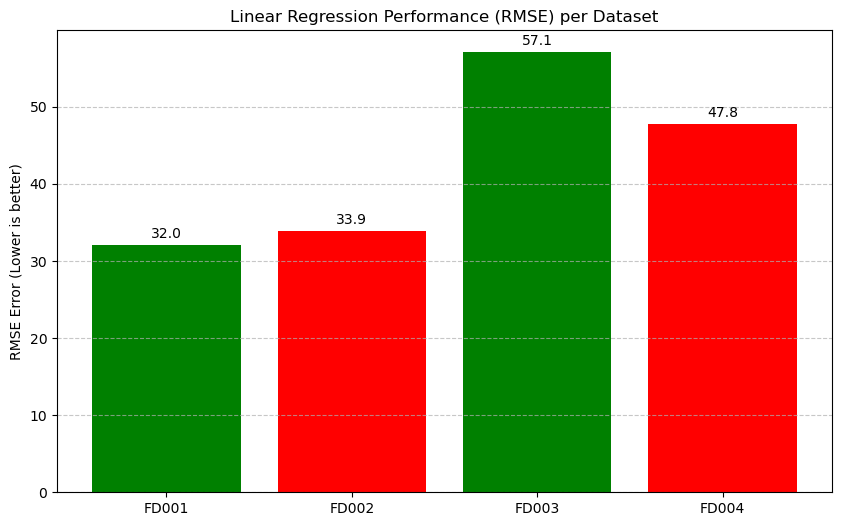

In [3]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
datasets = ['FD001', 'FD002', 'FD003', 'FD004']
results = []

print("--- Starting Evaluation (Linear Regression) ---")

for file_id in datasets:
    # 1. Load Processed Data
    try:
        train_path = f'../data/processed/train_{file_id}_processed.csv'
        test_path = f'../data/processed/test_{file_id}_processed.csv'
        rul_path = f'../data/raw/RUL_{file_id}.txt'

        df_train = pd.read_csv(train_path)
        df_test = pd.read_csv(test_path)
        df_rul = pd.read_csv(rul_path, header=None, names=['RUL_actual'])
    except FileNotFoundError:
        print(f"Error: Data not found for {file_id}. Skipping.")
        continue

    # 2. Define Features (exclude metadata columns)
    features = [col for col in df_train.columns if col not in ['unit_nr', 'time_cycles', 'RUL']]
    
    X_train = df_train[features]
    y_train = df_train['RUL']

    # 3. Train Model (Simple Linear Regression)
    model = LinearRegression()
    model.fit(X_train, y_train)

    # 4. Evaluate on Test Data
    # We predict the RUL at the LAST available cycle for each unit in the test set
    test_last_cycle = df_test.groupby('unit_nr').last().reset_index()
    X_test = test_last_cycle[features]
    
    y_pred = model.predict(X_test)
    y_true = df_rul['RUL_actual']

    # 5. Calculate Metrics
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    # Store results
    results.append({
        'Dataset': file_id, 
        'RMSE': rmse, 
        'R2_Score': r2,
        'Num_Features': len(features)
    })
    
    print(f"Dataset {file_id}: RMSE = {rmse:.2f} | R2 = {r2:.4f}")

# --- Present Final Table ---
results_df = pd.DataFrame(results)
print("\n--- FINAL SUMMARY ---")
# If not in Jupyter, use print(results_df) instead of display()
try:
    display(results_df)
except:
    print(results_df)

# --- Visualization ---
plt.figure(figsize=(10, 6))
# Colors: Green for "easier" datasets, Red for "harder/complex" ones
colors = ['green', 'red', 'green', 'red']
bars = plt.bar(results_df['Dataset'], results_df['RMSE'], color=colors)

plt.title('Linear Regression Performance (RMSE) per Dataset')
plt.ylabel('RMSE Error (Lower is better)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, round(yval, 1), ha='center', va='bottom')

plt.show()

--- Starting Evaluation (Linear Regression) ---

Processing FD001...
-> RMSE: 32.04 | R2: 0.4055


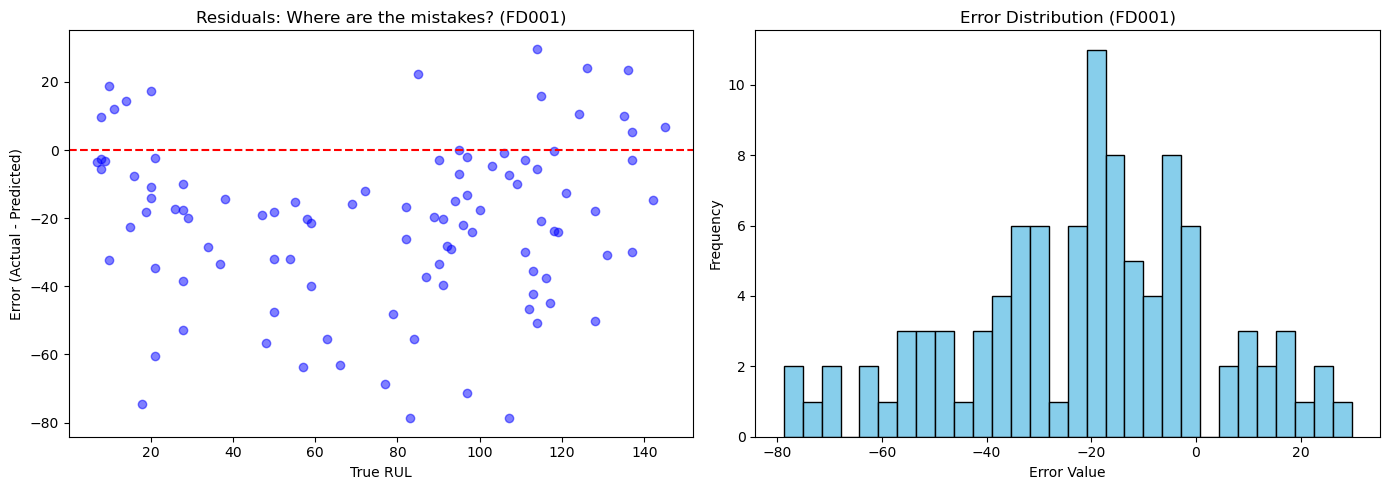


Processing FD002...
-> RMSE: 33.94 | R2: 0.6016


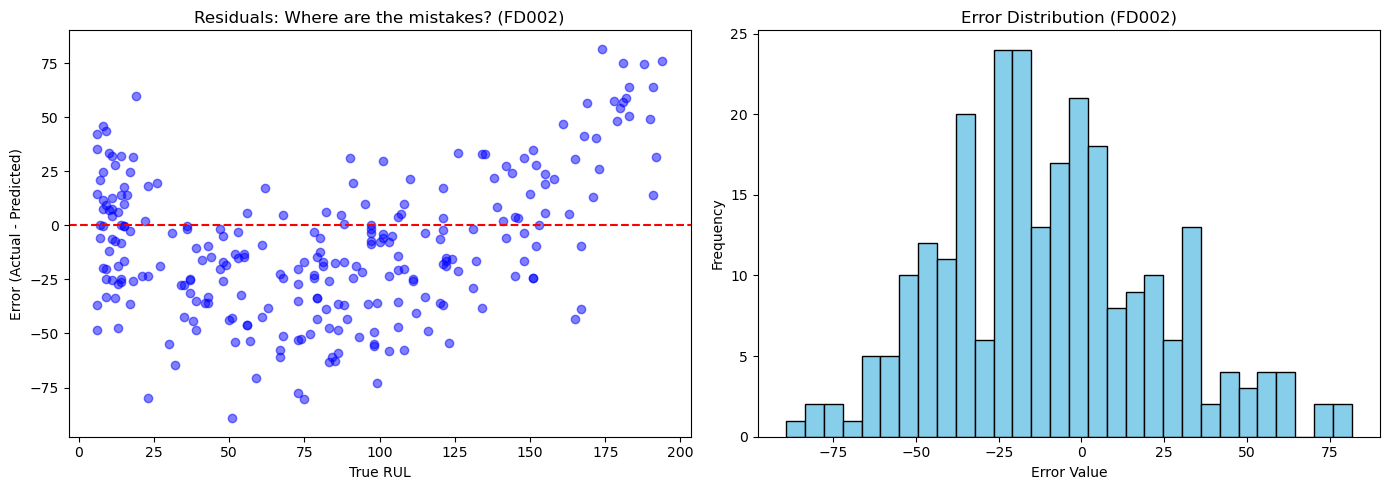


Processing FD003...
-> RMSE: 57.08 | R2: -0.9011


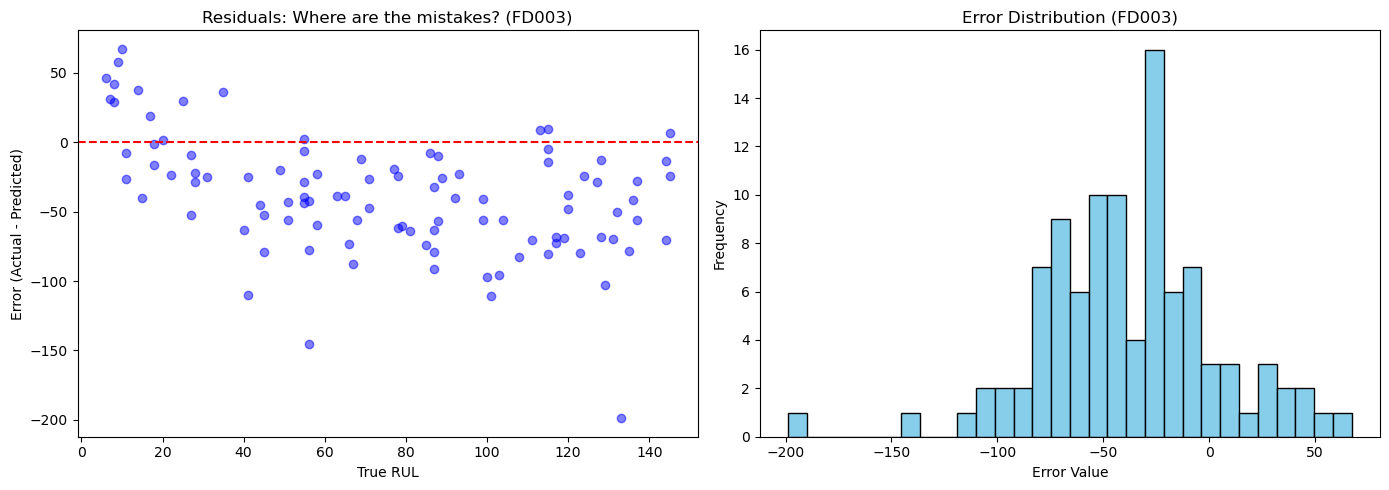


Processing FD004...
-> RMSE: 47.76 | R2: 0.2328


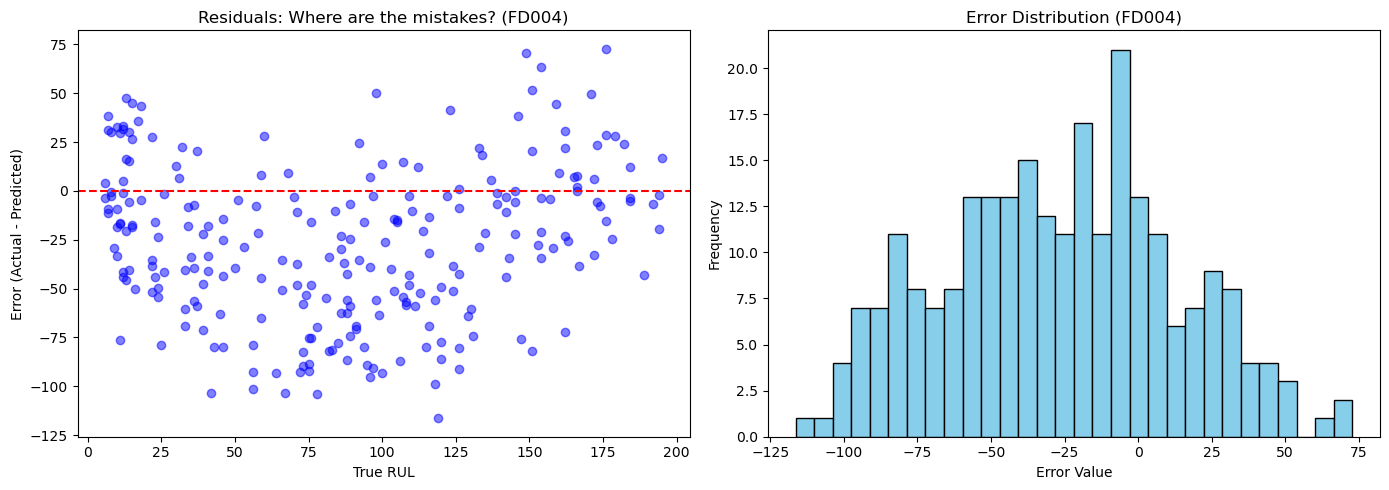

In [4]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
datasets = ['FD001', 'FD002', 'FD003', 'FD004']
results = []
# Ajusta o base_path conforme a tua estrutura de pastas real
base_path_processed = '../data/processed' 
base_path_raw = '../data/raw'

print("--- Starting Evaluation (Linear Regression) ---")

for file_id in datasets:
    print(f"\nProcessing {file_id}...")
    
    # 1. Load Processed Data
    try:
        train_path = f'{base_path_processed}/train_{file_id}_processed.csv'
        test_path = f'{base_path_processed}/test_{file_id}_processed.csv'
        rul_path = f'{base_path_raw}/RUL_{file_id}.txt'

        df_train = pd.read_csv(train_path)
        df_test = pd.read_csv(test_path)
        df_rul = pd.read_csv(rul_path, header=None, names=['RUL_actual'])
    except FileNotFoundError:
        print(f"Error: Data not found for {file_id}. Skipping.")
        continue

    # 2. Define Features
    features = [col for col in df_train.columns if col not in ['unit_nr', 'time_cycles', 'RUL']]
    
    X_train = df_train[features]
    y_train = df_train['RUL']

    # 3. Train Model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # 4. Predict on Test Data (Last Cycle)
    test_last_cycle = df_test.groupby('unit_nr').last().reset_index()
    X_test = test_last_cycle[features]
    
    y_pred = model.predict(X_test)
    y_true = df_rul['RUL_actual']

    # 5. Calculate Metrics
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    results.append({
        'Dataset': file_id, 
        'RMSE': rmse, 
        'R2_Score': r2,
        'Num_Features': len(features)
    })
    
    print(f"-> RMSE: {rmse:.2f} | R2: {r2:.4f}")

    # --- RESIDUAL ANALYSIS (Inserido aqui) ---
    residuals = y_true - y_pred
    
    # Criar uma figura com 2 gráficos lado a lado para este dataset
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gráfico 1: Scatter (Onde erramos mais?)
    axes[0].scatter(y_true, residuals, alpha=0.5, color='blue')
    axes[0].axhline(y=0, color='r', linestyle='--')
    axes[0].set_xlabel('True RUL')
    axes[0].set_ylabel('Error (Actual - Predicted)')
    axes[0].set_title(f'Residuals: Where are the mistakes? ({file_id})')
    
    # Gráfico 2: Histograma (Distribuição do Erro)
    axes[1].hist(residuals, bins=30, edgecolor='k', color='skyblue')
    axes[1].set_xlabel('Error Value')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'Error Distribution ({file_id})')
    
    plt.tight_layout()
    plt.show()